# 03 - Entrenamiento

Entrenar y comparar modelos de forecasting.

In [6]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import sklearn.dummy
import streamlit as st
import holidays

# Sustituir por el modelo y las variables del proyecto.
model = sklearn.dummy.DummyRegressor(strategy='mean')

In [18]:
ventas = pd.read_csv('../data/raw/entrenamiento/ventas.csv')
competencia = pd.read_csv('../data/raw/entrenamiento/competencia.csv')

ventas['fecha'] = pd.to_datetime(ventas['fecha'], errors='coerce')
competencia['fecha'] = pd.to_datetime(competencia['fecha'], errors='coerce')

ventas.head(), competencia.head()

(       fecha producto_id                            nombre categoria  \
 0 2021-10-25    PROD_001          Nike Air Zoom Pegasus 40   Running   
 1 2021-10-25    PROD_002              Adidas Ultraboost 23   Running   
 2 2021-10-25    PROD_003               Asics Gel Nimbus 25   Running   
 3 2021-10-25    PROD_004  New Balance Fresh Foam X 1080v12   Running   
 4 2021-10-25    PROD_005                Nike Dri-FIT Miler   Running   
 
          subcategoria  precio_base  es_estrella  unidades_vendidas  \
 0  Zapatillas Running          115         True                  6   
 1  Zapatillas Running          135         True                 10   
 2  Zapatillas Running           85        False                  2   
 3  Zapatillas Running           75        False                  2   
 4        Ropa Running           35        False                  2   
 
    precio_venta  ingresos  
 0        118.36    710.16  
 1        136.82   1368.20  
 2         84.93    169.86  
 3         75.42

In [21]:
df = ventas.merge(
    competencia,
    on=['fecha', 'producto_id'],
    how='left',
    validate='one_to_one'
)

print(f'DataFrame integrado: {df.shape[0]} filas x {df.shape[1]} columnas')
print(f'Filas de ventas conservadas: {len(df) == len(ventas)}')
print(f'Nulos introducidos por la integracion: {df.isna().sum().sum()}')
display(df.head())

DataFrame integrado: 3552 filas x 13 columnas
Filas de ventas conservadas: True
Nulos introducidos por la integracion: 0


,fecha,producto_id,nombre,categoria,subcategoria,precio_base,es_estrella,unidades_vendidas,precio_venta,ingresos,Amazon,Decathlon,Deporvillage
0,2021-10-25,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,6,118.36,710.16,82.96,111.88,97.43
1,2021-10-25,PROD_002,Adidas Ultraboost 23,Running,Zapatillas Running,135,True,10,136.82,1368.20,112.56,108.61,115.58
2,2021-10-25,PROD_003,Asics Gel Nimbus 25,Running,Zapatillas Running,85,False,2,84.93,169.86,79.79,78.44,80.11
3,2021-10-25,PROD_004,New Balance Fresh Foam X 1080v12,Running,Zapatillas Running,75,False,2,75.42,150.84,72.60,67.29,74.45
4,2021-10-25,PROD_005,Nike Dri-FIT Miler,Running,Ropa Running,35,False,2,35.87,71.74,37.71,33.60,33.07


In [19]:
columnas_ventas_esperadas = [
    'fecha', 'producto_id', 'nombre', 'categoria', 'subcategoria',
    'precio_base', 'es_estrella', 'unidades_vendidas', 'precio_venta',
    'ingresos'
]
columnas_faltantes = [columna for columna in columnas_ventas_esperadas if columna not in ventas.columns]
columnas_extra = [columna for columna in ventas.columns if columna not in columnas_ventas_esperadas]

nulos_por_variable = ventas.isna().sum().to_frame('nulos')
nulos_por_variable['porcentaje_nulos'] = (nulos_por_variable['nulos'] / len(ventas) * 100).round(2)
duplicados_totales = ventas.duplicated().sum()
duplicados_clave = ventas.duplicated(subset=['fecha', 'producto_id']).sum()
tipos_variables = ventas.dtypes.astype(str).to_frame('tipo')
valores_unicos = ventas.nunique(dropna=False).to_frame('valores_unicos')

fechas_convertidas = pd.to_datetime(ventas['fecha'], errors='coerce')
fechas_invalidas = fechas_convertidas.isna().sum()
valores_negativos = ventas[['precio_base', 'unidades_vendidas', 'precio_venta', 'ingresos']].lt(0).sum()

estadisticos_descriptivos = ventas.describe(include='all').T
informe_calidad = pd.DataFrame({
    'metrica': [
        'filas', 'columnas', 'duplicados_totales', 'duplicados_fecha_producto',
        'fechas_invalidas', 'columnas_faltantes', 'columnas_extra',
        'variables_con_nulos', 'variables_con_valores_negativos'
    ],
    'resultado': [
        len(ventas), len(ventas.columns), duplicados_totales, duplicados_clave,
        fechas_invalidas, len(columnas_faltantes), len(columnas_extra),
        int((nulos_por_variable['nulos'] > 0).sum()), int((valores_negativos > 0).sum())
    ]
})

problemas_calidad = (
    duplicados_totales > 0
    or duplicados_clave > 0
    or fechas_invalidas > 0
    or nulos_por_variable['nulos'].sum() > 0
    or len(columnas_faltantes) > 0
    or (valores_negativos > 0).any()
)

print('INFORME FINAL DE CALIDAD DE DATOS: ventas')
print('=' * 55)
print(f'Tamano: {ventas.shape[0]} filas x {ventas.shape[1]} columnas')
print(f'Estado general: {"REVISAR" if problemas_calidad else "OK"}')
print('\n1. Tipos y valores unicos por variable')
display(pd.concat([tipos_variables, valores_unicos], axis=1))
print('\n2. Nulos por variable')
display(nulos_por_variable)
print('\n3. Duplicados')
print(f'Duplicados de filas completas: {duplicados_totales}')
print(f'Duplicados de la clave fecha + producto_id: {duplicados_clave}')
print('\n4. Fechas y valores negativos')
print(f'Fechas invalidas: {fechas_invalidas}')
display(valores_negativos.to_frame('valores_negativos'))
print('\n5. Descriptivos')
display(estadisticos_descriptivos)
print('\n6. Validacion de estructura')
print(f'Columnas faltantes: {columnas_faltantes if columnas_faltantes else "ninguna"}')
print(f'Columnas extra: {columnas_extra if columnas_extra else "ninguna"}')
print('\nResumen de calidad')
display(informe_calidad)

INFORME FINAL DE CALIDAD DE DATOS: ventas
Tamano: 3552 filas x 10 columnas
Estado general: OK

1. Tipos y valores unicos por variable


,tipo,valores_unicos
fecha,datetime64[us],148
producto_id,str,24
nombre,str,24
categoria,str,4
subcategoria,str,16
precio_base,int64,21
es_estrella,bool,2
unidades_vendidas,int64,52
precio_venta,float64,2537
ingresos,float64,3033



2. Nulos por variable


,nulos,porcentaje_nulos
fecha,0,0.0
producto_id,0,0.0
nombre,0,0.0
categoria,0,0.0
subcategoria,0,0.0
precio_base,0,0.0
es_estrella,0,0.0
unidades_vendidas,0,0.0
precio_venta,0,0.0
ingresos,0,0.0



3. Duplicados
Duplicados de filas completas: 0
Duplicados de la clave fecha + producto_id: 0

4. Fechas y valores negativos
Fechas invalidas: 0


,valores_negativos
precio_base,0
unidades_vendidas,0
precio_venta,0
ingresos,0



5. Descriptivos


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
fecha,3552,NaN,NaN,NaN,2023-05-13 18:00:00,2021-10-25 00:00:00,2022-08-03 18:00:00,2023-05-13 12:00:00,2024-02-20 12:00:00,2024-11-30 00:00:00,NaN
producto_id,3552,24,PROD_001,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nombre,3552,24,Nike Air Zoom Pegasus 40,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
categoria,3552,4,Running,1184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subcategoria,3552,16,Zapatillas Running,888,NaN,NaN,NaN,NaN,NaN,NaN,NaN
precio_base,3552.0,NaN,NaN,NaN,123.125,20.0,48.75,72.5,118.75,830.0,165.576753
es_estrella,3552,2,False,2516,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unidades_vendidas,3552.0,NaN,NaN,NaN,4.87866,1.0,2.0,3.0,5.0,85.0,6.31102
precio_venta,3552.0,NaN,NaN,NaN,121.816546,19.0,47.2125,71.81,118.22,854.22,164.017963
ingresos,3552.0,NaN,NaN,NaN,605.972323,19.46,131.535,216.57,639.6375,14508.4,1079.071192



6. Validacion de estructura
Columnas faltantes: ninguna
Columnas extra: ninguna

Resumen de calidad


,metrica,resultado
0,filas,3552
1,columnas,10
2,duplicados_totales,0
3,duplicados_fecha_producto,0
4,fechas_invalidas,0
5,columnas_faltantes,0
6,columnas_extra,0
7,variables_con_nulos,0
8,variables_con_valores_negativos,0


In [20]:
columnas_competencia_esperadas = [
    'fecha', 'producto_id', 'Amazon', 'Decathlon', 'Deporvillage'
]
columnas_competencia_faltantes = [
    columna for columna in columnas_competencia_esperadas if columna not in competencia.columns
]
columnas_competencia_extra = [
    columna for columna in competencia.columns if columna not in columnas_competencia_esperadas
]

competencia_nulos_por_variable = competencia.isna().sum().to_frame('nulos')
competencia_nulos_por_variable['porcentaje_nulos'] = (
    competencia_nulos_por_variable['nulos'] / len(competencia) * 100
).round(2)
competencia_duplicados_totales = competencia.duplicated().sum()
competencia_duplicados_clave = competencia.duplicated(
    subset=['fecha', 'producto_id']
).sum()
competencia_tipos_variables = competencia.dtypes.astype(str).to_frame('tipo')
competencia_valores_unicos = competencia.nunique(dropna=False).to_frame('valores_unicos')

competencia_fechas_convertidas = pd.to_datetime(competencia['fecha'], errors='coerce')
competencia_fechas_invalidas = competencia_fechas_convertidas.isna().sum()
competencia_valores_negativos = competencia[
    ['Amazon', 'Decathlon', 'Deporvillage']
].lt(0).sum()
competencia_estadisticos_descriptivos = competencia.describe(include='all').T
competencia_problemas_calidad = (
    competencia_duplicados_totales > 0
    or competencia_duplicados_clave > 0
    or competencia_fechas_invalidas > 0
    or competencia_nulos_por_variable['nulos'].sum() > 0
    or len(columnas_competencia_faltantes) > 0
    or (competencia_valores_negativos > 0).any()
)
competencia_informe_calidad = pd.DataFrame({
    'metrica': [
        'filas', 'columnas', 'duplicados_totales', 'duplicados_fecha_producto',
        'fechas_invalidas', 'columnas_faltantes', 'columnas_extra',
        'variables_con_nulos', 'variables_con_valores_negativos'
    ],
    'resultado': [
        len(competencia), len(competencia.columns), competencia_duplicados_totales,
        competencia_duplicados_clave, competencia_fechas_invalidas,
        len(columnas_competencia_faltantes), len(columnas_competencia_extra),
        int((competencia_nulos_por_variable['nulos'] > 0).sum()),
        int((competencia_valores_negativos > 0).sum())
    ]
})

print('INFORME FINAL DE CALIDAD DE DATOS: competencia')
print('=' * 58)
print(f'Tamano: {competencia.shape[0]} filas x {competencia.shape[1]} columnas')
print(f'Estado general: {"REVISAR" if competencia_problemas_calidad else "OK"}')
print('\n1. Tipos y valores unicos por variable')
display(pd.concat([competencia_tipos_variables, competencia_valores_unicos], axis=1))
print('\n2. Nulos por variable')
display(competencia_nulos_por_variable)
print('\n3. Duplicados')
print(f'Duplicados de filas completas: {competencia_duplicados_totales}')
print(f'Duplicados de la clave fecha + producto_id: {competencia_duplicados_clave}')
print('\n4. Fechas y valores negativos')
print(f'Fechas invalidas: {competencia_fechas_invalidas}')
display(competencia_valores_negativos.to_frame('valores_negativos'))
print('\n5. Descriptivos')
display(competencia_estadisticos_descriptivos)
print('\n6. Validacion de estructura')
print(
    f'Columnas faltantes: '
    f'{columnas_competencia_faltantes if columnas_competencia_faltantes else "ninguna"}'
)
print(
    f'Columnas extra: '
    f'{columnas_competencia_extra if columnas_competencia_extra else "ninguna"}'
)
print('\nResumen de calidad')
display(competencia_informe_calidad)

INFORME FINAL DE CALIDAD DE DATOS: competencia
Tamano: 3552 filas x 5 columnas
Estado general: OK

1. Tipos y valores unicos por variable


,tipo,valores_unicos
fecha,datetime64[us],148
producto_id,str,24
Amazon,float64,3125
Decathlon,float64,3001
Deporvillage,float64,3105



2. Nulos por variable


,nulos,porcentaje_nulos
fecha,0,0.0
producto_id,0,0.0
Amazon,0,0.0
Decathlon,0,0.0
Deporvillage,0,0.0



3. Duplicados
Duplicados de filas completas: 0
Duplicados de la clave fecha + producto_id: 0

4. Fechas y valores negativos
Fechas invalidas: 0


,valores_negativos
Amazon,0
Decathlon,0
Deporvillage,0



5. Descriptivos


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
fecha,3552,NaN,NaN,NaN,2023-05-13 18:00:00,2021-10-25 00:00:00,2022-08-03 18:00:00,2023-05-13 12:00:00,2024-02-20 12:00:00,2024-11-30 00:00:00,NaN
producto_id,3552,24,PROD_001,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Amazon,3552.0,NaN,NaN,NaN,118.623407,16.85,47.1175,73.18,114.3425,858.35,156.095628
Decathlon,3552.0,NaN,NaN,NaN,111.412182,15.45,43.285,66.285,111.1725,867.3375,148.508132
Deporvillage,3552.0,NaN,NaN,NaN,118.894628,16.77,47.31,72.7,114.985,932.325,160.216448



6. Validacion de estructura
Columnas faltantes: ninguna
Columnas extra: ninguna

Resumen de calidad


,metrica,resultado
0,filas,3552
1,columnas,5
2,duplicados_totales,0
3,duplicados_fecha_producto,0
4,fechas_invalidas,0
5,columnas_faltantes,0
6,columnas_extra,0
7,variables_con_nulos,0
8,variables_con_valores_negativos,0


## Analisis exploratorio de `df`

Se revisan estructura, calidad, distribuciones y patrones temporales de las ventas integradas con la competencia.

In [22]:
# Preparacion de variables para el analisis exploratorio.
df = df.copy()
df['fecha'] = pd.to_datetime(df['fecha'], errors='coerce')
df['año'] = df['fecha'].dt.year
df['dia_semana'] = df['fecha'].dt.day_name()
df['dia_semana_numero'] = df['fecha'].dt.dayofweek

orden_dias = [
    'lunes', 'martes', 'miércoles', 'jueves',
    'viernes', 'sábado', 'domingo'
]
traduccion_dias = {
    'Monday': 'lunes', 'Tuesday': 'martes', 'Wednesday': 'miércoles',
    'Thursday': 'jueves', 'Friday': 'viernes', 'Saturday': 'sábado',
    'Sunday': 'domingo'
}
df['dia_semana'] = df['dia_semana'].map(traduccion_dias)

black_fridays = {}
for año in sorted(df['año'].dropna().unique()):
    primer_dia_noviembre = pd.Timestamp(year=int(año), month=11, day=1)
    dias_hasta_jueves = (3 - primer_dia_noviembre.dayofweek) % 7
    cuarto_jueves = primer_dia_noviembre + pd.Timedelta(days=dias_hasta_jueves + 21)
    black_fridays[int(año)] = cuarto_jueves + pd.Timedelta(days=1)

df['es_black_friday'] = df['fecha'].map(
    lambda fecha: fecha.normalize() in set(black_fridays.values())
    if pd.notna(fecha) else False
)

print(f'Dimensiones de df: {df.shape[0]} filas x {df.shape[1]} columnas')
print(f'Periodo: {df["fecha"].min().date()} a {df["fecha"].max().date()}')
print(f'Años disponibles: {sorted(df["año"].dropna().unique().astype(int).tolist())}')
display(df.head())

Dimensiones de df: 3552 filas x 17 columnas
Periodo: 2021-10-25 a 2024-11-30
Años disponibles: [2021, 2022, 2023, 2024]


,fecha,producto_id,nombre,categoria,subcategoria,precio_base,es_estrella,unidades_vendidas,precio_venta,ingresos,Amazon,Decathlon,Deporvillage,año,dia_semana,dia_semana_numero,es_black_friday
0,2021-10-25,PROD_001,Nike Air Zoom Pegasus 40,Running,Zapatillas Running,115,True,6,118.36,710.16,82.96,111.88,97.43,2021,lunes,0,False
1,2021-10-25,PROD_002,Adidas Ultraboost 23,Running,Zapatillas Running,135,True,10,136.82,1368.20,112.56,108.61,115.58,2021,lunes,0,False
2,2021-10-25,PROD_003,Asics Gel Nimbus 25,Running,Zapatillas Running,85,False,2,84.93,169.86,79.79,78.44,80.11,2021,lunes,0,False
3,2021-10-25,PROD_004,New Balance Fresh Foam X 1080v12,Running,Zapatillas Running,75,False,2,75.42,150.84,72.60,67.29,74.45,2021,lunes,0,False
4,2021-10-25,PROD_005,Nike Dri-FIT Miler,Running,Ropa Running,35,False,2,35.87,71.74,37.71,33.60,33.07,2021,lunes,0,False


In [23]:
# Resumen estadistico y calidad de df.
print('Tipos de datos y valores nulos')
display(pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'porcentaje_nulos': (df.isna().mean() * 100).round(2),
    'valores_unicos': df.nunique(dropna=False)
}))

print('Estadisticos descriptivos de variables numericas')
display(df.describe().T)

print('Resumen de ventas por año')
display(
    df.groupby('año', dropna=False)
    .agg(
        unidades_vendidas=('unidades_vendidas', 'sum'),
        ingresos=('ingresos', 'sum'),
        productos=('producto_id', 'nunique'),
        registros=('producto_id', 'size')
    )
    .reset_index()
)

Tipos de datos y valores nulos


,tipo,nulos,porcentaje_nulos,valores_unicos
fecha,datetime64[us],0,0.0,148
producto_id,str,0,0.0,24
nombre,str,0,0.0,24
categoria,str,0,0.0,4
subcategoria,str,0,0.0,16
precio_base,int64,0,0.0,21
es_estrella,bool,0,0.0,2
unidades_vendidas,int64,0,0.0,52
precio_venta,float64,0,0.0,2537
ingresos,float64,0,0.0,3033


Estadisticos descriptivos de variables numericas


,count,mean,min,25%,50%,75%,max,std
fecha,3552,2023-05-13 18:00:00,2021-10-25 00:00:00,2022-08-03 18:00:00,2023-05-13 12:00:00,2024-02-20 12:00:00,2024-11-30 00:00:00,NaN
precio_base,3552.0,123.125,20.0,48.75,72.5,118.75,830.0,165.576753
unidades_vendidas,3552.0,4.87866,1.0,2.0,3.0,5.0,85.0,6.31102
precio_venta,3552.0,121.816546,19.0,47.2125,71.81,118.22,854.22,164.017963
ingresos,3552.0,605.972323,19.46,131.535,216.57,639.6375,14508.4,1079.071192
Amazon,3552.0,118.623407,16.85,47.1175,73.18,114.3425,858.35,156.095628
Decathlon,3552.0,111.412182,15.45,43.285,66.285,111.1725,867.3375,148.508132
Deporvillage,3552.0,118.894628,16.77,47.31,72.7,114.985,932.325,160.216448
año,3552.0,2022.5,2021.0,2021.75,2022.5,2023.25,2024.0,1.118191
dia_semana_numero,3552.0,2.959459,0.0,1.0,3.0,5.0,6.0,1.986306


Resumen de ventas por año


,año,unidades_vendidas,ingresos,productos,registros
0,2021,3766,457895.40,24,888
1,2022,4325,525338.06,24,888
2,2023,4805,597492.83,24,888
3,2024,4433,571687.40,24,888


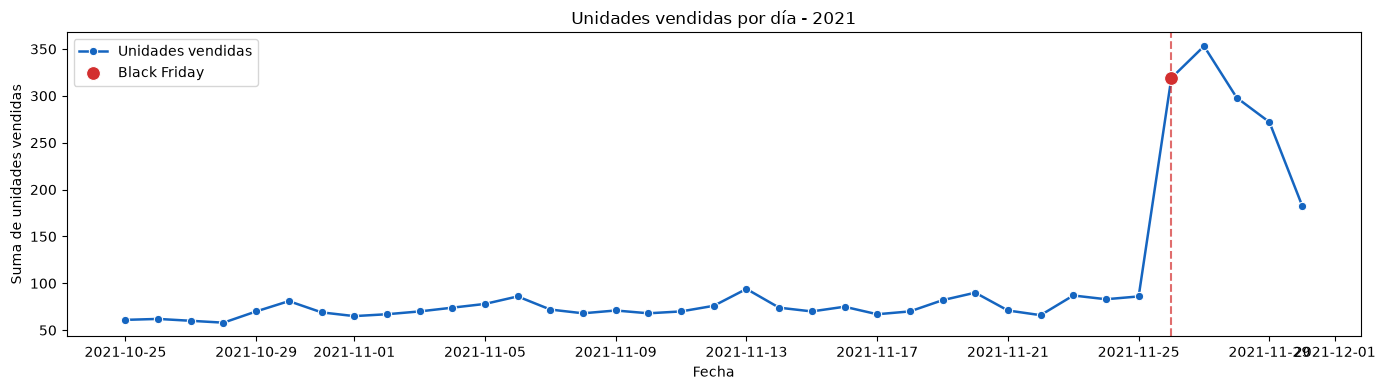

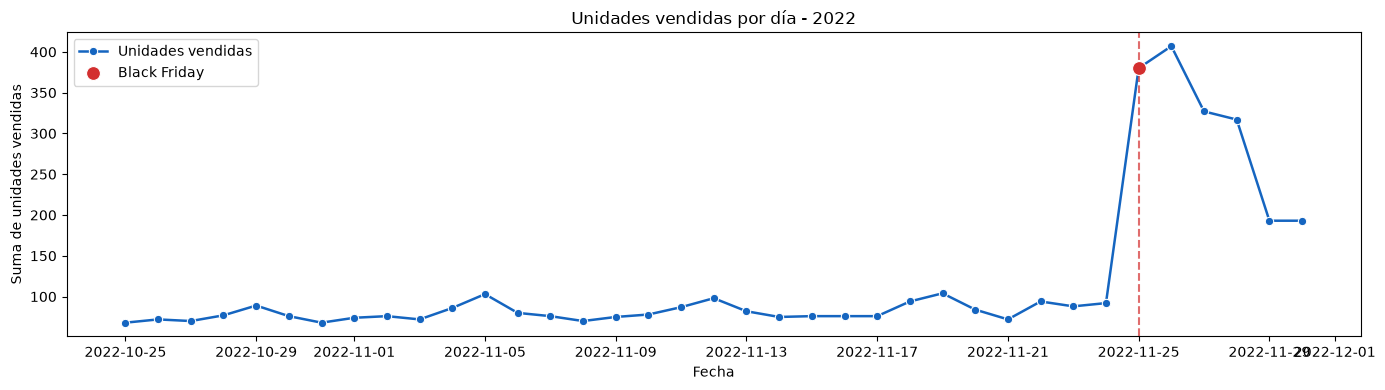

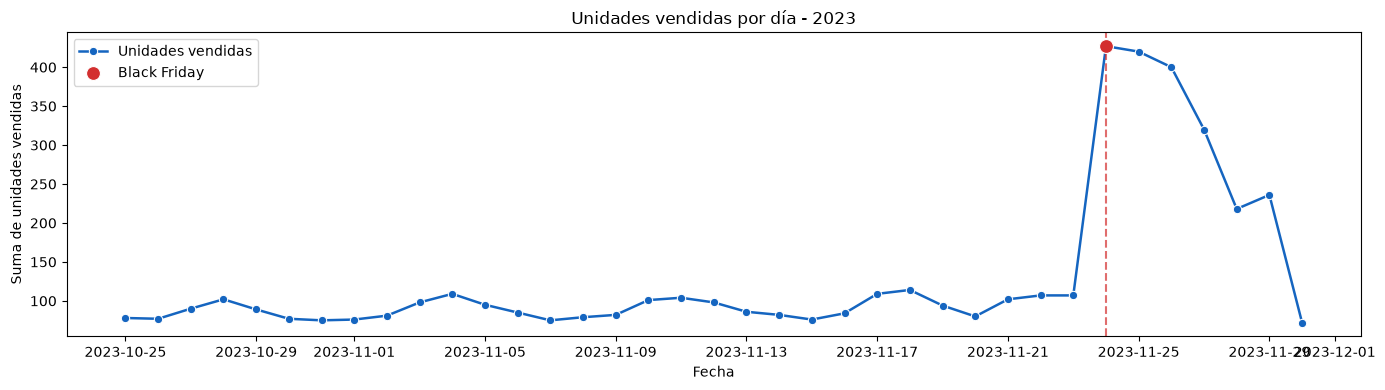

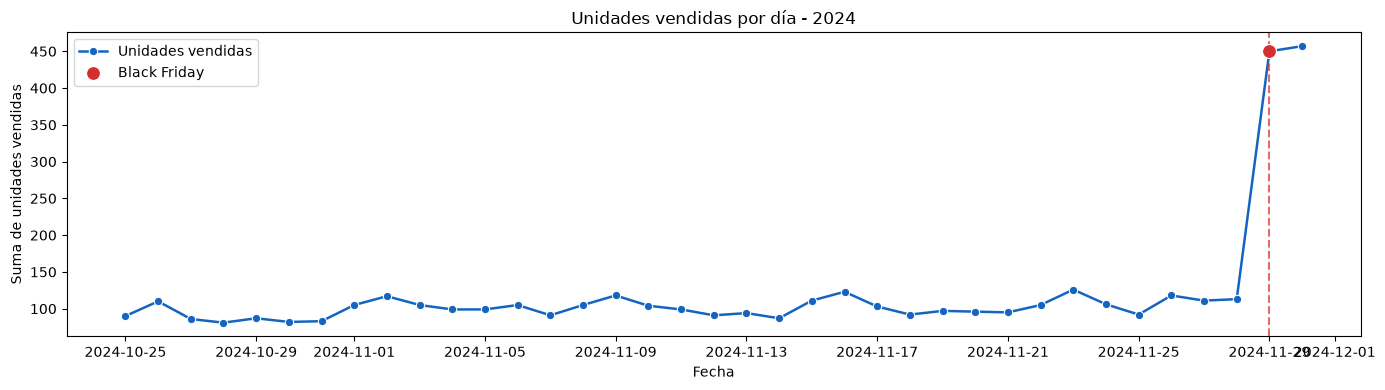

In [24]:
# Evolucion diaria de unidades vendidas, con un grafico independiente por año.
ventas_diarias = (
    df.dropna(subset=['fecha'])
    .groupby(['año', 'fecha'], as_index=False)['unidades_vendidas']
    .sum()
)

for año in sorted(ventas_diarias['año'].unique()):
    datos_año = ventas_diarias[ventas_diarias['año'] == año]
    figura, eje = plt.subplots(figsize=(14, 4))
    sns.lineplot(
        data=datos_año,
        x='fecha',
        y='unidades_vendidas',
        marker='o',
        linewidth=1.8,
        color='#1565c0',
        ax=eje,
        label='Unidades vendidas'
    )
    fecha_black_friday = black_fridays.get(int(año))
    if fecha_black_friday is not None and fecha_black_friday.year == int(año):
        datos_black_friday = datos_año[datos_año['fecha'] == fecha_black_friday]
        if not datos_black_friday.empty:
            sns.scatterplot(
                data=datos_black_friday,
                x='fecha',
                y='unidades_vendidas',
                color='#d32f2f',
                s=100,
                zorder=5,
                ax=eje,
                label='Black Friday'
            )
        eje.axvline(fecha_black_friday, color='#d32f2f', linestyle='--', alpha=0.7)
    eje.set_title(f'Unidades vendidas por día - {int(año)}')
    eje.set_xlabel('Fecha')
    eje.set_ylabel('Suma de unidades vendidas')
    eje.legend()
    figura.tight_layout()
    plt.show()

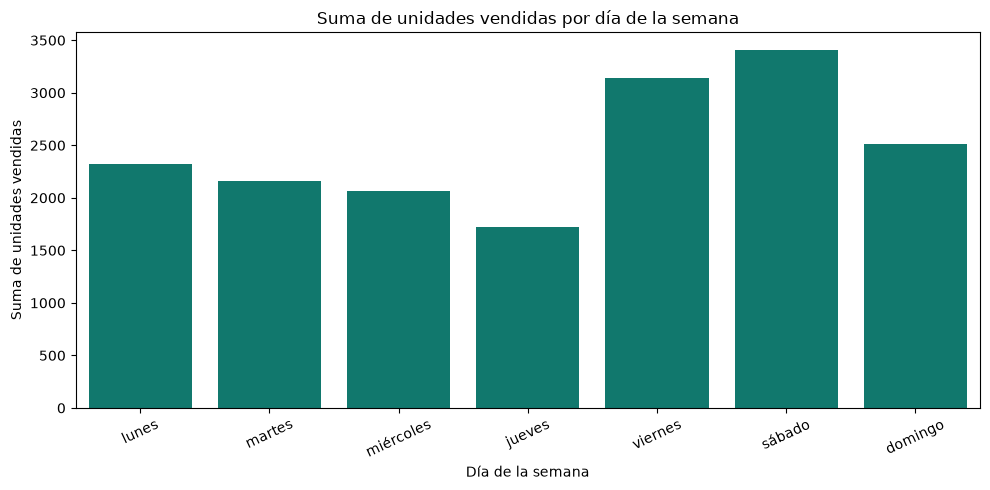

In [25]:
# Suma de unidades vendidas por dia de la semana.
unidades_por_dia = (
    df.groupby(['dia_semana_numero', 'dia_semana'], as_index=False)['unidades_vendidas']
    .sum()
    .sort_values('dia_semana_numero')
)

figura, eje = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=unidades_por_dia,
    x='dia_semana',
    y='unidades_vendidas',
    order=orden_dias,
    color='#00897b',
    errorbar=None,
    ax=eje
)
eje.set_title('Suma de unidades vendidas por día de la semana')
eje.set_xlabel('Día de la semana')
eje.set_ylabel('Suma de unidades vendidas')
eje.tick_params(axis='x', rotation=25)
figura.tight_layout()
plt.show()

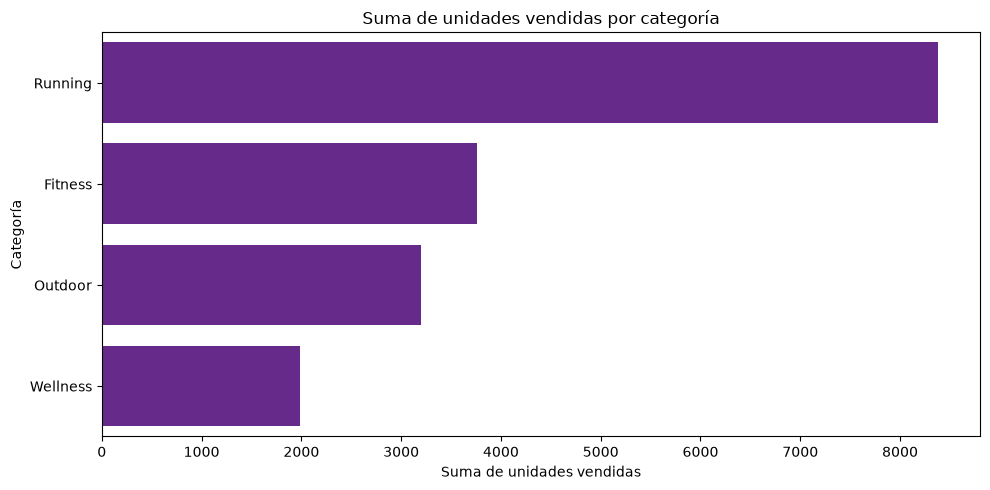

In [26]:
# Suma de unidades vendidas por categoria.
unidades_por_categoria = (
    df.groupby('categoria', as_index=False)['unidades_vendidas']
    .sum()
    .sort_values('unidades_vendidas', ascending=False)
)

figura, eje = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=unidades_por_categoria,
    x='unidades_vendidas',
    y='categoria',
    color='#6a1b9a',
    errorbar=None,
    ax=eje
)
eje.set_title('Suma de unidades vendidas por categoría')
eje.set_xlabel('Suma de unidades vendidas')
eje.set_ylabel('Categoría')
figura.tight_layout()
plt.show()

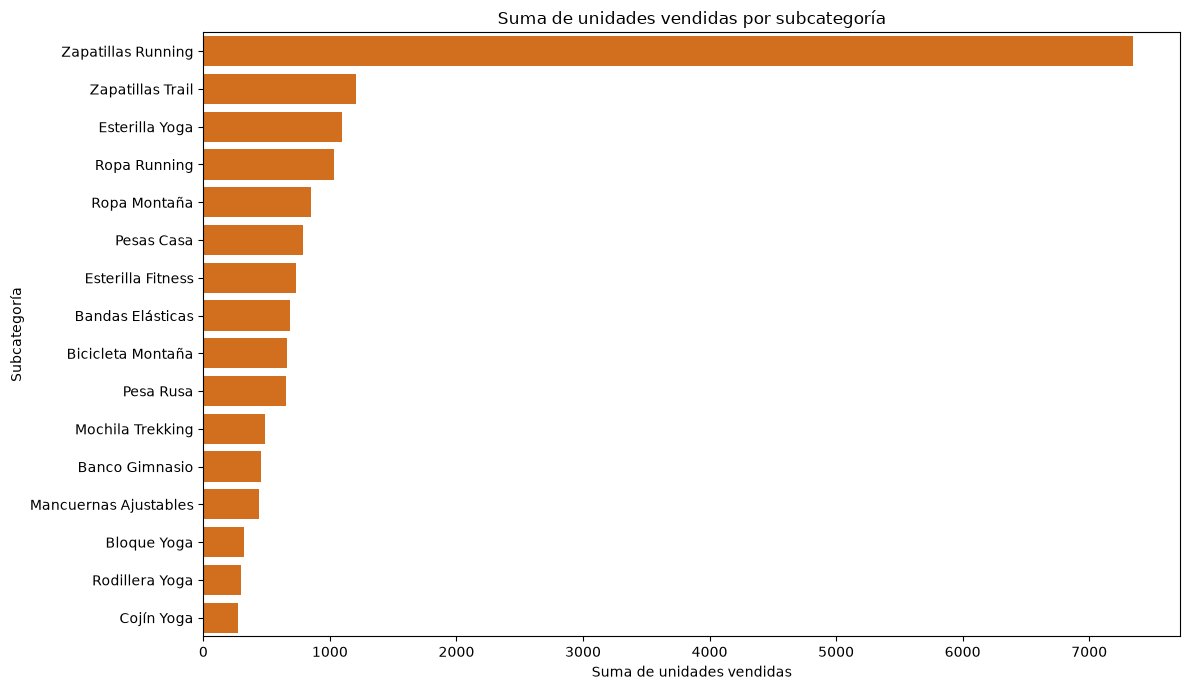

In [27]:
# Suma de unidades vendidas por subcategoria.
unidades_por_subcategoria = (
    df.groupby('subcategoria', as_index=False)['unidades_vendidas']
    .sum()
    .sort_values('unidades_vendidas', ascending=False)
)

figura, eje = plt.subplots(figsize=(12, 7))
sns.barplot(
    data=unidades_por_subcategoria,
    x='unidades_vendidas',
    y='subcategoria',
    color='#ef6c00',
    errorbar=None,
    ax=eje
)
eje.set_title('Suma de unidades vendidas por subcategoría')
eje.set_xlabel('Suma de unidades vendidas')
eje.set_ylabel('Subcategoría')
figura.tight_layout()
plt.show()

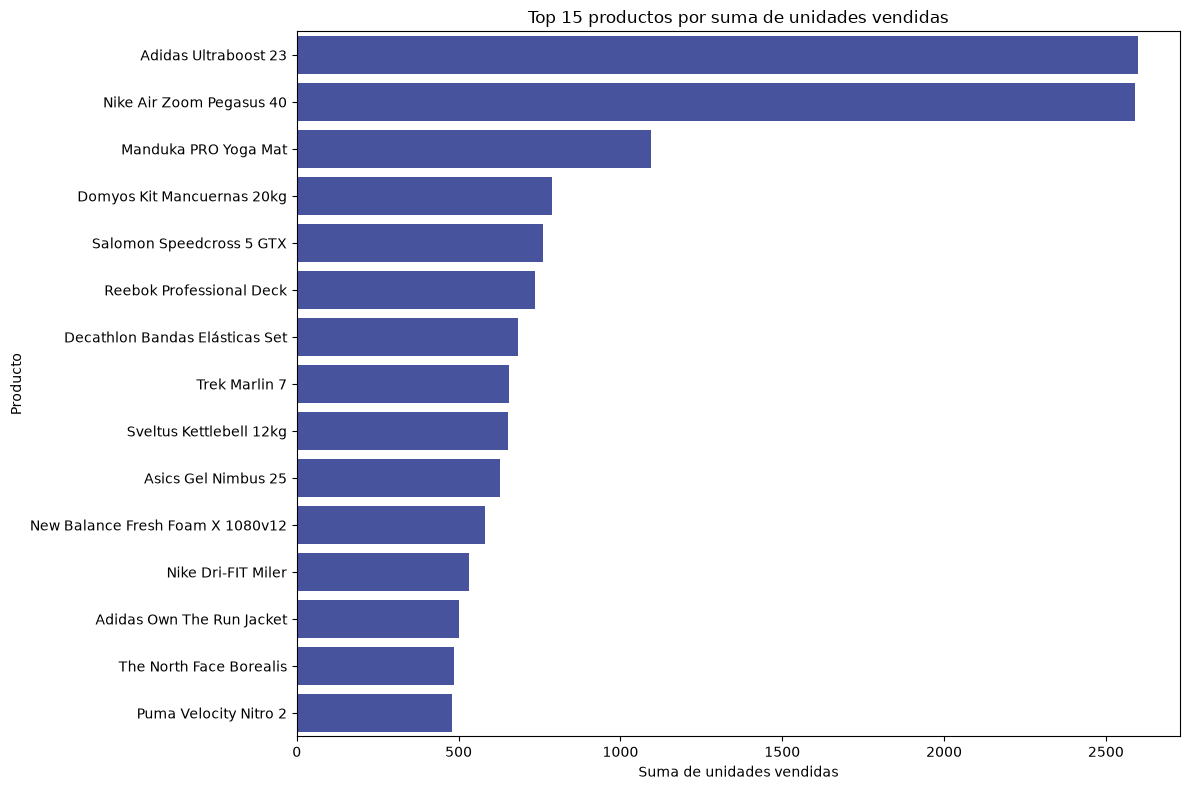

,producto_id,nombre,unidades_vendidas
1,PROD_002,Adidas Ultraboost 23,2599
0,PROD_001,Nike Air Zoom Pegasus 40,2590
20,PROD_021,Manduka PRO Yoga Mat,1094
11,PROD_012,Domyos Kit Mancuernas 20kg,788
14,PROD_015,Salomon Speedcross 5 GTX,760
10,PROD_011,Reebok Professional Deck,735
12,PROD_013,Decathlon Bandas Elásticas Set,685
15,PROD_016,Trek Marlin 7,657
13,PROD_014,Sveltus Kettlebell 12kg,653
2,PROD_003,Asics Gel Nimbus 25,629


In [28]:
# Productos con mayor suma de unidades vendidas.
top_productos = (
    df.groupby(['producto_id', 'nombre'], as_index=False)['unidades_vendidas']
    .sum()
    .sort_values('unidades_vendidas', ascending=False)
    .head(15)
)

figura, eje = plt.subplots(figsize=(12, 8))
sns.barplot(
    data=top_productos,
    x='unidades_vendidas',
    y='nombre',
    color='#3949ab',
    errorbar=None,
    ax=eje
)
eje.set_title('Top 15 productos por suma de unidades vendidas')
eje.set_xlabel('Suma de unidades vendidas')
eje.set_ylabel('Producto')
figura.tight_layout()
plt.show()

display(top_productos)

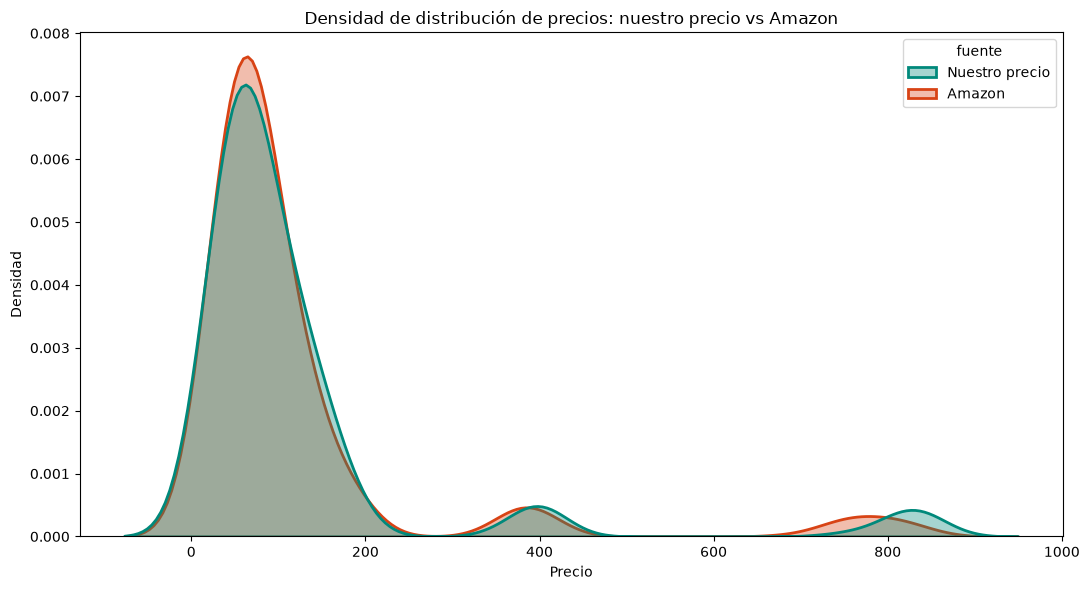

Resumen de precios comparados


,count,mean,std,min,25%,50%,75%,max
fuente,,,,,,,,
Amazon,3552.0,118.62,156.10,16.85,47.12,73.18,114.34,858.35
Nuestro precio,3552.0,121.82,164.02,19.00,47.21,71.81,118.22,854.22


In [29]:
# Densidad de los precios propios y de Amazon.
precios = df[['precio_venta', 'Amazon']].melt(
    var_name='fuente',
    value_name='precio'
).dropna(subset=['precio'])
precios['fuente'] = precios['fuente'].replace({
    'precio_venta': 'Nuestro precio',
    'Amazon': 'Amazon'
})

figura, eje = plt.subplots(figsize=(11, 6))
sns.kdeplot(
    data=precios,
    x='precio',
    hue='fuente',
    fill=True,
    common_norm=False,
    alpha=0.35,
    linewidth=2,
    palette={'Nuestro precio': '#00897b', 'Amazon': '#d84315'},
    ax=eje
)
eje.set_title('Densidad de distribución de precios: nuestro precio vs Amazon')
eje.set_xlabel('Precio')
eje.set_ylabel('Densidad')
figura.tight_layout()
plt.show()

print('Resumen de precios comparados')
display(precios.groupby('fuente')['precio'].describe().round(2))